# Top roles — APAC

Roles engaged in the last 12 months for APAC-vertical clients, with JP Title / JP Category
backfilled from Staff Central designations.

Sections: setup → extract → title helpers → load → format → ruleset → review & exports.

## Setup

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd

### Config

In [2]:
DATA_DIR = Path.home() / "Desktop/Projects/Data/Top_roles_APAC_adhoc"   # outside the repo (confidential)
SOURCES = {
    "sc_engagement": {"path": DATA_DIR / "SC Engagement List2026-11-15 09_48_04 (1).xlsx"},
    "mystaff": {"path": DATA_DIR / "CONFIDENTIAL Mystaff 11092026 - Copy.xlsx", "sheet": "MyStaff"},
    "staff_report": {"path": DATA_DIR / "Staff Report with Details 16-Nov-2026 [CONFIDENTIAL] (1).xlsx"},
}
SOURCE_MODE = "excel"

# Ruleset
DATE_THRESHOLD = pd.Timestamp("2025-11-01")   # engagements on/after this date = last 12 months
APAC_VERTICALS = ["AUFS", "AUHE", "AURE", "AUBC", "APAC", "AURW", "AUMS"]

In [3]:
# Source column -> internal name
MYSTAFF_CONTRACT = {
    "Shortcode":              "shortcode",
    "Client":                 "company_name",
    "Active":                 "active",
    "CRM Company ID":         "crm_company_id",        # = HubSpot Record ID
    "Website URL":            "website_url",
    "Office Address State":   "office_state",
    "Office Address Country": "office_country",
    "Industry Hubspot":       "industry_hubspot",      # same taxonomy as HubSpot 'Industry'
    "Industry Roll Up":       "industry_rollup",       # Cloudstaff grouping (fallback)
    "Custom_Division (Hubspot)": "vertical",
    "Total Staff":            "cs_staff_current",      # Cloudstaff seats, NOT company size
    "Date of First Staff Engagement": "client_since",  # first staff start: time as a client
    "Tenure":                 "client_tenure_band",    # MyStaff's own band, e.g. "4. 13-18 months" (used when the date is blank)
    # staff added per month (gross adds), summed into seats_added_6m (seat growth signal)
    "Month to Date Movement Add": "seats_added_mtd",
    "Last Month Movement Add":    "seats_added_m1",
    "Month-2 Movement Add":       "seats_added_m2",
    "Month-3 Movement Add":       "seats_added_m3",
    "Month-4 Movement Add":       "seats_added_m4",
    "Month-5 Movement Add":       "seats_added_m5",
}

# Not used yet: extract_sc_engagement reads the whole sheet
SC_ENGAGEMENT_CONTRACT = {
    "Shortcode":              "shortcode",
    "Client":                 "company_name",
    "Active":                 "active",
    "CRM Company ID":         "crm_company_id",        # = HubSpot Record ID
    "Website URL":            "website_url",
    "Office Address State":   "office_state",
    "Office Address Country": "office_country",
    "Industry Hubspot":       "industry_hubspot",      # same taxonomy as HubSpot 'Industry'
    "Industry Roll Up":       "industry_rollup",       # Cloudstaff grouping (fallback)
    "Total Staff":            "cs_staff_current",      # Cloudstaff seats, NOT company size
    "Date of First Staff Engagement": "client_since",  # first staff start: time as a client
    "Tenure":                 "client_tenure_band",    # MyStaff's own band, e.g. "4. 13-18 months" (used when the date is blank)
    # staff added per month (gross adds), summed into seats_added_6m (seat growth signal)
    "Month to Date Movement Add": "seats_added_mtd",
    "Last Month Movement Add":    "seats_added_m1",
    "Month-2 Movement Add":       "seats_added_m2",
    "Month-3 Movement Add":       "seats_added_m3",
    "Month-4 Movement Add":       "seats_added_m4",
    "Month-5 Movement Add":       "seats_added_m5",
}

## Extract

In [4]:
def validate_contract(df, contract, source):
    missing = set(contract.values()) - set(df.columns)
    if missing:
        raise ValueError(f"{source}: missing contract fields {sorted(missing)}")
    return df[list(contract.values())]


def extract_mystaff(cfg=SOURCES["mystaff"]):
    if SOURCE_MODE == "excel":
        raw = pd.read_excel(cfg["path"], sheet_name=cfg["sheet"], usecols=list(MYSTAFF_CONTRACT))
        n = len(raw)
        raw = raw.dropna(subset=["Shortcode"])        # the export has ~1M formatted-but-empty rows
        print(f"mystaff: dropped {n - len(raw):,} empty spreadsheet rows")
    else:
        raise NotImplementedError("MyStaff DB extract: TODO (client table, same fields as MYSTAFF_CONTRACT)")
    return validate_contract(raw.rename(columns=MYSTAFF_CONTRACT), MYSTAFF_CONTRACT, "mystaff")


def extract_sc_engagement(cfg=SOURCES["sc_engagement"]):
    if SOURCE_MODE == "excel":
        raw = pd.read_excel(cfg["path"])
    else:
        raise NotImplementedError("SC Engagement Contract not")
    return raw


def extract_staff_report(cfg=SOURCES["staff_report"]):
    if SOURCE_MODE == "excel":
        raw = pd.read_excel(cfg["path"])
    else:
        raise NotImplementedError("Staff Central Contract not")
    return raw

## Title helpers

`strip_title` removes level/seniority noise from a title; `backfill_jp` fills missing JP Title Base / JP Category with a strict cascade (ambiguous keys are left blank, not guessed).

In [5]:
# Typos and inconsistent spellings seen in the data
TYPO_FIXES = {
    r"\bSpeclialist\b": "Specialist",
    r"\bSpecialst\b": "Specialist",
    r"\bFullstack\b": "Full Stack",
    r"â€“": "–",
    r"â€”": "—",
}


def _fix_typos(s: pd.Series) -> pd.Series:
    s = s.astype("string")
    for pattern, repl in TYPO_FIXES.items():
        s = s.str.replace(pattern, repl, regex=True)
    return s


def _strip_seniority(s: pd.Series) -> pd.Series:
    """Drop level / seniority / numbering noise from a title (no typo fixes)."""
    return (s.astype("string")
            # "Level 1", "Level2", "Level 10" anywhere
            .str.replace(r"\bLevel\s*\d+\b", "", regex=True, flags=re.I)
            # Seniority words
            .str.replace(r"\b(Senior|Sr\.?|Junior|Jr\.?)(?=\s|$)", "", regex=True, flags=re.I)
            # Trailing roman numerals: "Engineer II", "Associate Software Engineer I"
            .str.replace(r"\s+(I{1,3}|IV)$", "", regex=True)
            # Digits glued to a word: "Coordinator2" -> "Coordinator" (keeps "3D")
            .str.replace(r"(?<=[A-Za-z])\d+\b", "", regex=True)
            # Tidy up: collapse spaces, drop leftover leading/trailing punctuation
            .str.replace(r"\s+", " ", regex=True)
            .str.strip(" ,-–—|")
            .str.strip()
            .replace("", pd.NA))


def strip_title(s: pd.Series) -> pd.Series:
    return _strip_seniority(_fix_typos(s))

In [6]:
def backfill_jp(
    df: pd.DataFrame,
    des_col: str = "Designation (All)",
    title_col: str = "JP Title (All)",
    cat_col: str = "JP Category (All)",
    min_support: int = 1,
    manual_title: dict | None = None,
    manual_cat: dict | None = None,
    use_designation_as_title: bool = True,
    keep_source_cols: bool = True,
):
    """
    Strictly backfill a stripped JP Title and JP Category.

    Rule: the most specific evidence wins; if that evidence is ambiguous
    (one key -> several values), the row is left blank rather than guessed.
    Lookups are built only from originally populated rows.

    Parameters
    ----------
    df : source dataframe (not modified)
    min_support : a key must be seen at least this many times to be trusted
    manual_title : {lowercase designation: title base} overrides, applied first
    manual_cat : {lowercase title base: category} overrides, applied first
    use_designation_as_title : allow the final step where a stripped
        Designation that is itself a known JP Title Base is used as the title
    keep_source_cols : keep 'title_source' / 'category_source' audit columns

    Returns
    -------
    out : dataframe with 'JP Title Base', 'JP Title Base (Filled)',
          'JP Category (Filled)' (+ source columns)
    reports : dict of DataFrames/Series for review
    """
    manual_title = manual_title or {}
    manual_cat = manual_cat or {}

    # ---------- helpers ----------
    def clean(s):
        return (_fix_typos(s)
                .str.replace(r"\s+", " ", regex=True)
                .str.strip()
                .replace("", pd.NA))

    def build_lookup(keys, values, support=min_support):
        tmp = pd.DataFrame({"k": keys, "v": values}).dropna()
        g = tmp.groupby("k")["v"].agg(n_values="nunique", value="first", support="size")
        g["status"] = np.select(
            [g["n_values"] > 1, g["support"] < support],
            ["ambiguous", "low_support"],
            default="unique",
        )
        return g

    def manual_lookup(mapping):
        return build_lookup(
            pd.Series([k.lower() for k in mapping.keys()], dtype="string"),
            pd.Series(list(mapping.values()), dtype="string"),
            1,
        )

    def cascade(start, steps):
        filled = start.copy()
        src = pd.Series(pd.NA, index=start.index, dtype="object")
        src[filled.notna()] = "original"
        open_ = filled.isna()

        for label, keys, lookup in steps:
            k = keys.where(open_)
            status = k.map(lookup["status"])
            value = k.map(lookup["value"])

            hit = open_ & status.eq("unique")
            filled[hit] = value[hit]
            src[hit] = label

            blocked = open_ & status.isin(["ambiguous", "low_support"])
            src[blocked] = "blocked: " + label + " " + status[blocked]

            open_ = open_ & ~hit & ~blocked

        src[open_] = "no_match"
        return filled, src

    def conflicts(keys, values):
        return (pd.DataFrame({"key": keys, "value": values})
                  .dropna()
                  .groupby("key")["value"]
                  .agg(lambda s: s.value_counts().to_dict())
                  .loc[lambda x: x.map(len) > 1])

    # ---------- prepare ----------
    missing = [c for c in (des_col, title_col, cat_col) if c not in df.columns]
    if missing:
        raise KeyError(f"Missing columns: {missing}")

    out = df.copy()
    des = clean(out[des_col])
    title = clean(out[title_col])
    cat = clean(out[cat_col])

    out["JP Title Base"] = _strip_seniority(title)

    des_key = des.str.lower()
    des_base_key = _strip_seniority(des).str.lower()
    title_key = title.str.lower()
    base_key = out["JP Title Base"].str.lower()

    # ---------- JP Title Base ----------
    title_steps = []
    if manual_title:
        title_steps.append(("manual", des_key, manual_lookup(manual_title)))
    title_steps += [
        ("designation_exact", des_key, build_lookup(des_key, out["JP Title Base"])),
        ("designation_base", des_base_key, build_lookup(des_base_key, out["JP Title Base"])),
    ]
    if use_designation_as_title:
        title_steps.append(
            ("designation_is_jp_title", des_base_key,
             build_lookup(base_key, out["JP Title Base"], 1))
        )

    out["JP Title Base (Filled)"], out["title_source"] = cascade(out["JP Title Base"], title_steps)

    # ---------- JP Category ----------
    filled_base_key = out["JP Title Base (Filled)"].str.lower()

    cat_steps = []
    if manual_cat:
        cat_steps.append(("manual", filled_base_key, manual_lookup(manual_cat)))
    cat_steps += [
        ("jp_title_exact", title_key, build_lookup(title_key, cat)),
        ("jp_title_base", filled_base_key, build_lookup(base_key, cat)),
        ("designation_exact", des_key, build_lookup(des_key, cat)),
    ]

    out["JP Category (Filled)"], out["category_source"] = cascade(cat, cat_steps)

    # ---------- reports ----------
    reports = {
        "title_source_counts": out["title_source"].value_counts(dropna=False),
        "category_source_counts": out["category_source"].value_counts(dropna=False),
        "title_conflicts": conflicts(des, out["JP Title Base"]),
        "category_conflicts": conflicts(out["JP Title Base"], cat),
        "unfilled_rows": out.loc[
            out["JP Category (Filled)"].isna() | out["JP Title Base (Filled)"].isna(),
            [des_col, title_col, "JP Title Base (Filled)", "JP Category (Filled)",
             "title_source", "category_source"],
        ],
    }

    if not keep_source_cols:
        out = out.drop(columns=["title_source", "category_source"])

    return out, reports

## Load

In [7]:
sc_engagement_raw = extract_sc_engagement()
ms_raw = extract_mystaff()          # ~1 min: large sheet
staff_report_raw = extract_staff_report()
print("mystaff:", ms_raw.shape)

mystaff: dropped 1,045,621 empty spreadsheet rows
mystaff: (1112, 19)


## Format

In [8]:
sc_engagement = sc_engagement_raw.copy()
sc_engagement["engagement_date"] = pd.to_datetime(sc_engagement["Engagement Date"])
sc_engagement = sc_engagement.rename(columns={"Shortcode": "shortcode"})

ms = ms_raw[["shortcode", "company_name", "crm_company_id", "office_country",
             "industry_hubspot", "industry_rollup", "vertical"]].copy()

staff_report = staff_report_raw[["CSID", "Designation (All)", "JP Title (All)", "JP Category (All)"]].copy()

## Apply ruleset

Last 12 months of engagements → join MyStaff (vertical, industry) and Staff Central (JP Title, Category) → backfill titles/categories → keep APAC verticals.

In [9]:
apac_roles_12m = sc_engagement[sc_engagement["engagement_date"] >= DATE_THRESHOLD].copy()
print(apac_roles_12m.shape)

# Joins
apac_roles_12m = apac_roles_12m.merge(ms, on="shortcode", how="left")             # MyStaff: vertical, industry
print(apac_roles_12m.shape)
apac_roles_12m = apac_roles_12m.merge(staff_report, on="CSID", how="left")       # Staff Central: JP Title, Category
print(apac_roles_12m.shape)

# Base title on the unfilled frame (backfill_jp recomputes it on its own copy)
apac_roles_12m["JP Title Base"] = strip_title(apac_roles_12m["JP Title (All)"])

# Backfill Title and Category with the cascading ruleset, then keep APAC verticals
apac_roles_12m_filled, reports = backfill_jp(apac_roles_12m)
apac_roles_12m_filled = apac_roles_12m_filled[apac_roles_12m_filled["vertical"].isin(APAC_VERTICALS)]
print(apac_roles_12m_filled.shape)

(4563, 15)
(4563, 21)
(4563, 24)
(1212, 29)


In [10]:
# Useful data extracts
clients_no_vertical = apac_roles_12m[apac_roles_12m["vertical"].isna()]["shortcode"].unique()
roles_mapping_df = (apac_roles_12m[["Designation (All)", "JP Title (All)", "JP Category (All)"]]
                    .dropna(how="all")
                    .copy())

In [11]:
APAC_VERTICALS

['AUFS', 'AUHE', 'AURE', 'AUBC', 'APAC', 'AURW', 'AUMS']

In [12]:
ms['vertical'].unique()

array(['AURE', nan, 'APAC', 'USBC', 'USRE', 'USTL', 'USHC', 'AUBC',
       'USIT', 'AMER', 'USAC', 'USFS', 'AUFS', 'AUMS', 'AURW', 'USDM',
       'USCL', 'EMEA', 'USEC', 'USLG', 'AUHE', 'USLS'], dtype=object)

## Review

In [13]:
# Backfill reports (only the last expression displays; swap in the one you need)
reports["title_source_counts"]
reports["category_source_counts"]
reports["category_conflicts"]   # title bases split across categories
reports["title_conflicts"]      # designations mapping to several title bases
reports["unfilled_rows"]        # what's left to resolve by hand

,Designation (All),JP Title (All),JP Title Base (Filled),JP Category (Filled),title_source,category_source
4,Accountant,NaN,<NA>,Accounting,blocked: designation_exact ambiguous,designation_exact
5,Accountant,NaN,<NA>,Accounting,blocked: designation_exact ambiguous,designation_exact
21,Senior Accountant,NaN,<NA>,<NA>,blocked: designation_exact ambiguous,blocked: designation_exact ambiguous
26,Travel Agent Level 1,NaN,<NA>,<NA>,no_match,no_match
40,Technical Support Specialist Level 2,NaN,Technical Support Specialist,<NA>,designation_exact,blocked: jp_title_base ambiguous
...,...,...,...,...,...,...
4522,Financial Accountant Level 1,NaN,<NA>,<NA>,blocked: designation_exact ambiguous,blocked: designation_exact ambiguous
4529,Graphic Designer II,NaN,<NA>,<NA>,blocked: designation_exact ambiguous,blocked: designation_exact ambiguous
4544,Technical Support II,NaN,<NA>,<NA>,blocked: designation_exact ambiguous,blocked: designation_exact ambiguous
4546,Senior CPA,NaN,<NA>,<NA>,no_match,no_match


In [14]:
reports["category_source_counts"]

category_source
original                                3112
jp_title_base                            590
blocked: designation_exact ambiguous     376
designation_exact                        145
no_match                                 141
blocked: jp_title_base ambiguous         106
jp_title_exact                            73
blocked: jp_title_exact ambiguous         20
Name: count, dtype: int64

In [15]:
apac_roles_12m['vertical'].unique()

array(['USDM', 'AUFS', nan, 'AUHE', 'USLG', 'USFS', 'USHC', 'USAC',
       'USEC', 'AURE', 'AUBC', 'USIT', 'USTL', 'APAC', 'AURW', 'USLS',
       'AUMS', 'AMER', 'USCL', 'USRE', 'EMEA', 'USBC'], dtype=object)

In [16]:
na_summary = (
    apac_roles_12m.isna().sum()
    .to_frame("na_count")
    .assign(na_pct=lambda d: (d["na_count"] / len(apac_roles_12m) * 100).round(2))
    .query("na_count > 0")
    .sort_values("na_count", ascending=False)
)
print(na_summary)

                    na_count  na_pct
Disengagement Date      2843   62.31
vertical                1861   40.78
crm_company_id          1859   40.74
company_name            1859   40.74
industry_hubspot        1859   40.74
office_country          1859   40.74
industry_rollup         1859   40.74
JP Category (All)       1451   31.80
JP Title Base           1350   29.59
JP Title (All)          1350   29.59
Middle Name              524   11.48
Designation (All)          2    0.04


## Top roles analysis

Top JP Titles and JP Categories across all APAC-vertical roles, and by vertical.
Uses the backfilled columns; rows still unmapped after backfill are counted separately, not ranked.

In [17]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

TITLE_COL = "JP Title Base (Filled)"
CAT_COL = "JP Category (Filled)"
TOP_N_TITLES = 15
TOP_N_CATS = 10
TOP_N_PER_VERTICAL = 5

roles = apac_roles_12m_filled
VERTICAL_ORDER = roles["vertical"].value_counts().index.tolist()   # largest vertical first


def top_counts(df, col, n=None):
    """Count and share of each value in `col` (share of mapped rows)."""
    counts = df[col].value_counts()            # NA excluded
    out = (counts.rename("roles").to_frame()
           .assign(share=lambda d: (d["roles"] / d["roles"].sum()).round(4),
                   rank=lambda d: range(1, len(d) + 1)))
    out.index.name = col
    return out.head(n) if n else out


def top_by_vertical(df, col, n=TOP_N_PER_VERTICAL):
    """Top `n` values of `col` within each vertical, with share of that vertical's mapped rows."""
    g = (df.dropna(subset=[col])
           .groupby(["vertical", col]).size().rename("roles").reset_index())
    g["share"] = (g["roles"] / g.groupby("vertical")["roles"].transform("sum")).round(4)
    g["rank"] = g.groupby("vertical")["roles"].rank(method="first", ascending=False).astype(int)
    g["vertical"] = pd.Categorical(g["vertical"], VERTICAL_ORDER, ordered=True)
    return g[g["rank"] <= n].sort_values(["vertical", "rank"]).reset_index(drop=True)


print(f"{len(roles):,} roles | unmapped title: {roles[TITLE_COL].isna().sum()} | "
      f"unmapped category: {roles[CAT_COL].isna().sum()}")

1,212 roles | unmapped title: 88 | unmapped category: 92


In [18]:
# Overall
top_titles = top_counts(roles, TITLE_COL, TOP_N_TITLES)
top_categories = top_counts(roles, CAT_COL, TOP_N_CATS)

# By vertical (long format: vertical, value, roles, share, rank)
top_titles_by_vertical = top_by_vertical(roles, TITLE_COL)
top_categories_by_vertical = top_by_vertical(roles, CAT_COL)

# Category share within each vertical (all categories x verticals), for the heatmap
category_share_by_vertical = (
    pd.crosstab(roles[CAT_COL], roles["vertical"], normalize="columns")
      .reindex(columns=VERTICAL_ORDER)
)
top_categories

,roles,share,rank
JP Category (Filled),,,
Accounting,315,0.2812,1
Virtual Assistant,122,0.1089,2
BPO Voice,108,0.0964,3
Real Estate,103,0.092,4
Administrative,72,0.0643,5
IT Software Development,60,0.0536,6
IT Network Systems/Support,50,0.0446,7
BPO Travel/Hospitality,28,0.025,8
Engineering Civil,22,0.0196,9


In [19]:
top_titles

,roles,share,rank
JP Title Base (Filled),,,
Property Management Assistant,62,0.0552,1
Customer Care Specialist,54,0.048,2
Accountant (General),44,0.0391,3
Tax Accountant,44,0.0391,4
Technical Support Specialist,40,0.0356,5
Executive Assistant,36,0.032,6
Bookkeeper,35,0.0311,7
Admin Assistant,33,0.0294,8
Virtual Assistant,30,0.0267,9


In [20]:
# Top titles per vertical, side by side: title — roles (share of vertical)
(top_titles_by_vertical
   .assign(label=lambda d: d[TITLE_COL] + " — " + d["roles"].astype(str)
                         + " (" + d["share"].map("{:.0%}".format) + ")")
   .pivot(index="rank", columns="vertical", values="label")
   .reindex(columns=VERTICAL_ORDER))

vertical,APAC,AURE,AUFS,AUMS,AUBC,AUHE,AURW
rank,,,,,,,
1,Customer Care Specialist — 50 (16%),Property Management Assistant — 51 (19%),Tax Accountant — 44 (23%),Service Desk — 20 (14%),Engineer — 11 (10%),Customer Support Specialist — 12 (16%),Property Management Assistant — 9 (75%)
2,Appointment Setter — 21 (7%),Executive Assistant — 26 (10%),Bookkeeper — 27 (14%),Salesforce Developer — 13 (9%),BIM Modeler — 10 (9%),Account Manager — 7 (9%),Bookkeeper — 1 (8%)
3,Technical Support Specialist — 21 (7%),Real Estate Administration - Sales & Property ...,Accountant (General) — 10 (5%),Technical Support Specialist — 13 (9%),Admin Assistant — 8 (7%),Back Office Specialist — 5 (7%),Real Estate Administration - Sales & Property ...
4,Accountant (General) — 18 (6%),Accountant (General) — 11 (4%),Client Services — 10 (5%),Network Engineer — 6 (4%),Quantity Surveyor — 7 (6%),Admin Assistant — 4 (5%),Real Estate Sales VA — 1 (8%)
5,Virtual Assistant — 18 (6%),Virtual Assistant — 11 (4%),Admin Assistant — 9 (5%),Software Engineer — 6 (4%),Accounts Payable Officer — 6 (5%),Accounting Officer — 3 (4%),<NA>


In [21]:
# Top categories per vertical, side by side
(top_categories_by_vertical
   .assign(label=lambda d: d[CAT_COL] + " (" + d["roles"].astype(str) + ")")
   .pivot(index="rank", columns="vertical", values="label")
   .reindex(columns=VERTICAL_ORDER))

vertical,APAC,AURE,AUFS,AUMS,AUBC,AUHE,AURW
rank,,,,,,,
1,BPO Voice (82),Real Estate (87),Accounting (121),IT Software Development (43),Accounting (30),Accounting (26),Real Estate (11)
2,Accounting (70),Virtual Assistant (63),Administrative (16),BPO Travel/Hospitality (20),Engineering Civil (21),BPO Workforce Management (8),Accounting (1)
3,Virtual Assistant (31),Accounting (55),BPO Voice (11),IT Network Systems/Support (19),Engineering Mechanical (15),Virtual Assistant (8),<NA>
4,IT Network Systems/Support (23),Administrative (16),BPO Healthcare (10),IT Software QA (14),Administrative (11),Administrative (6),<NA>
5,Administrative (21),Legal Specialist (8),Virtual Assistant (7),Accounting (12),Virtual Assistant (6),BPO Voice (6),<NA>


### Visuals

In [22]:
# Chart styling
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
BAR = "#2a78d6"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#ffffff", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])

plt.rcParams.update({
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK, "axes.edgecolor": GRID,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def ranked_barh(data, title, subtitle, ax=None):
    """Horizontal ranked bar chart of `data['roles']`, labelled with count and share."""
    data = data.iloc[::-1]                                  # largest at top
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 0.38 * len(data) + 1.4))
    bars = ax.barh(data.index.astype(str), data["roles"], color=BAR, height=0.7)
    ax.bar_label(bars, labels=[f"{r}  ({s:.0%})" for r, s in zip(data["roles"], data["share"])],
                 padding=4, color=INK_2, fontsize=9)
    ax.set_title(title, pad=22)
    ax.text(0, 1.01, subtitle, transform=ax.transAxes, color=INK_2, fontsize=9.5)
    ax.set_xlabel("Roles engaged")
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.set_xlim(0, data["roles"].max() * 1.18)
    plt.tight_layout()
    return ax


period = f"engaged since {DATE_THRESHOLD:%b %Y}"
n_title_mapped = roles[TITLE_COL].notna().sum()
n_cat_mapped = roles[CAT_COL].notna().sum()

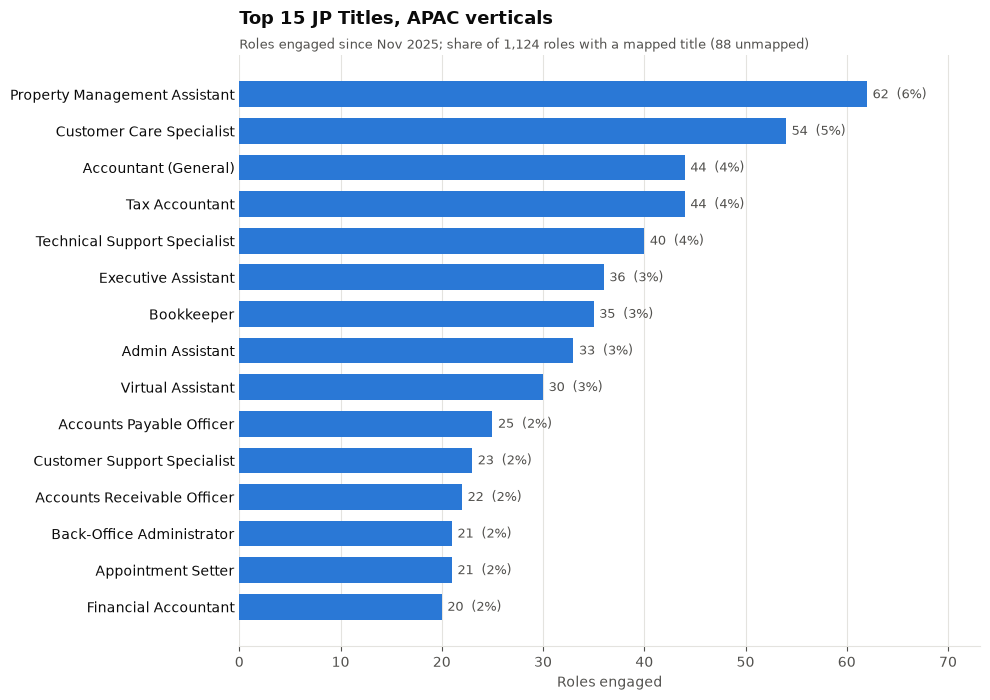

In [23]:
# 1. Top JP Titles (overall)
ranked_barh(top_titles, f"Top {TOP_N_TITLES} JP Titles, APAC verticals",
            f"Roles {period}; share of {n_title_mapped:,} roles with a mapped title "
            f"({len(roles) - n_title_mapped} unmapped)")
plt.show()

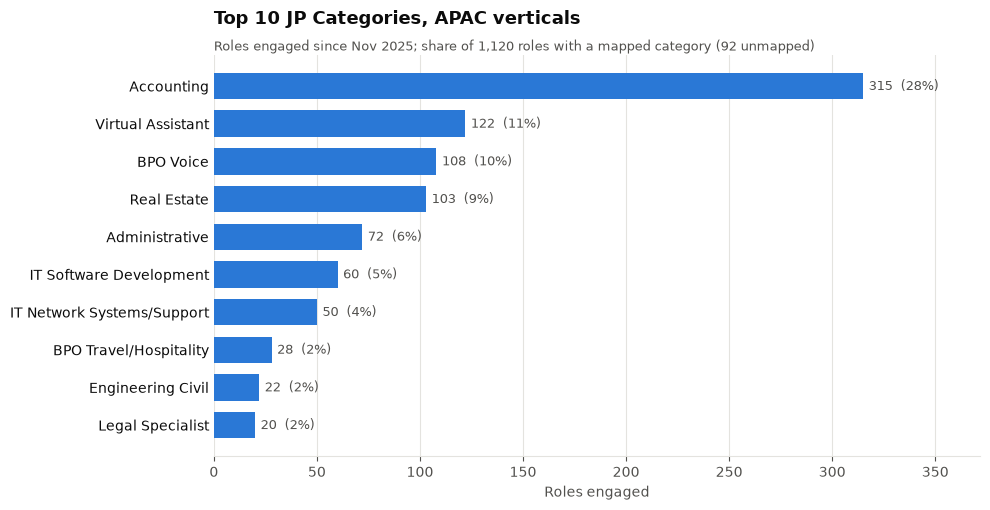

In [24]:
# 2. Top JP Categories (overall)
ranked_barh(top_categories, f"Top {TOP_N_CATS} JP Categories, APAC verticals",
            f"Roles {period}; share of {n_cat_mapped:,} roles with a mapped category "
            f"({len(roles) - n_cat_mapped} unmapped)")
plt.show()

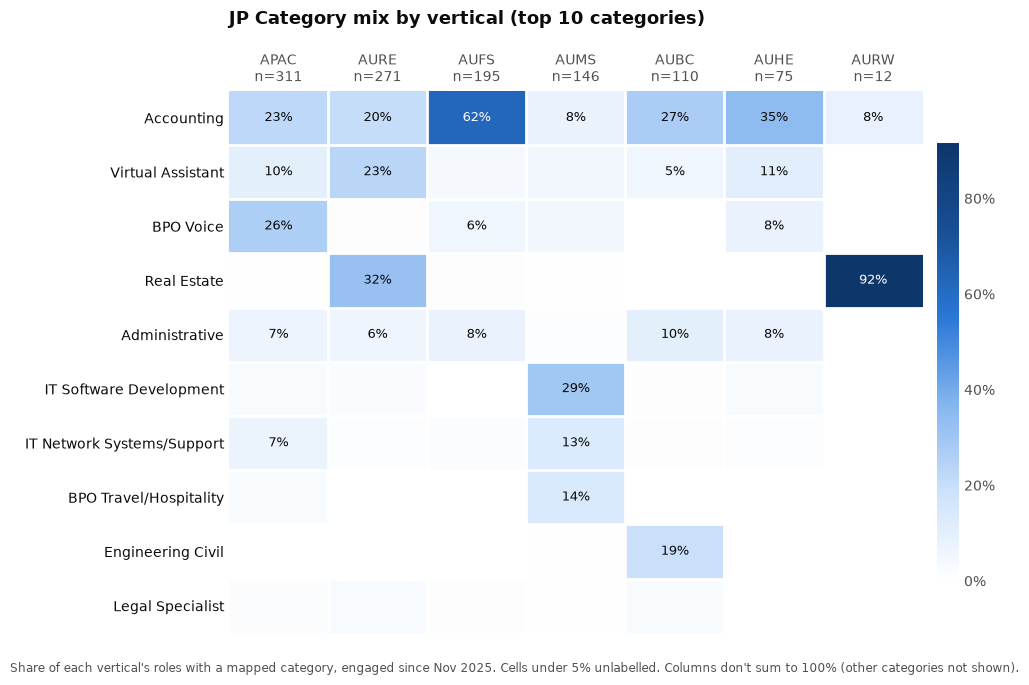

In [25]:
# 3. JP Category mix by vertical (top categories overall; % of each vertical's mapped roles)
heat = category_share_by_vertical.loc[top_categories.index]
n_by_vertical = roles.dropna(subset=[CAT_COL])["vertical"].value_counts().reindex(VERTICAL_ORDER)

fig, ax = plt.subplots(figsize=(10, 0.5 * len(heat) + 1.8))
im = ax.imshow(heat.values, cmap=SEQ_BLUE, vmin=0, vmax=heat.values.max(), aspect="auto")

ax.set_xticks(range(heat.shape[1]),
              [f"{v}\nn={n}" for v, n in n_by_vertical.items()])
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
# white gaps between cells
ax.set_xticks([x - 0.5 for x in range(1, heat.shape[1])], minor=True)
ax.set_yticks([y - 0.5 for y in range(1, heat.shape[0])], minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", length=0)

# label cells >= 5% (darker cells get light text)
for (i, j), v in np.ndenumerate(heat.values):
    if v >= 0.05:
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="white" if v > heat.values.max() * 0.55 else INK)

ax.set_title(f"JP Category mix by vertical (top {TOP_N_CATS} categories)", pad=48)
fig.text(0.0, 0.0, f"Share of each vertical's roles with a mapped category, {period}. "
         "Cells under 5% unlabelled. Columns don't sum to 100% (other categories not shown).",
         color=INK_2, fontsize=8.5, ha="left", va="bottom")
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=lambda x, _: f"{x:.0%}")
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=INK_2, length=0)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

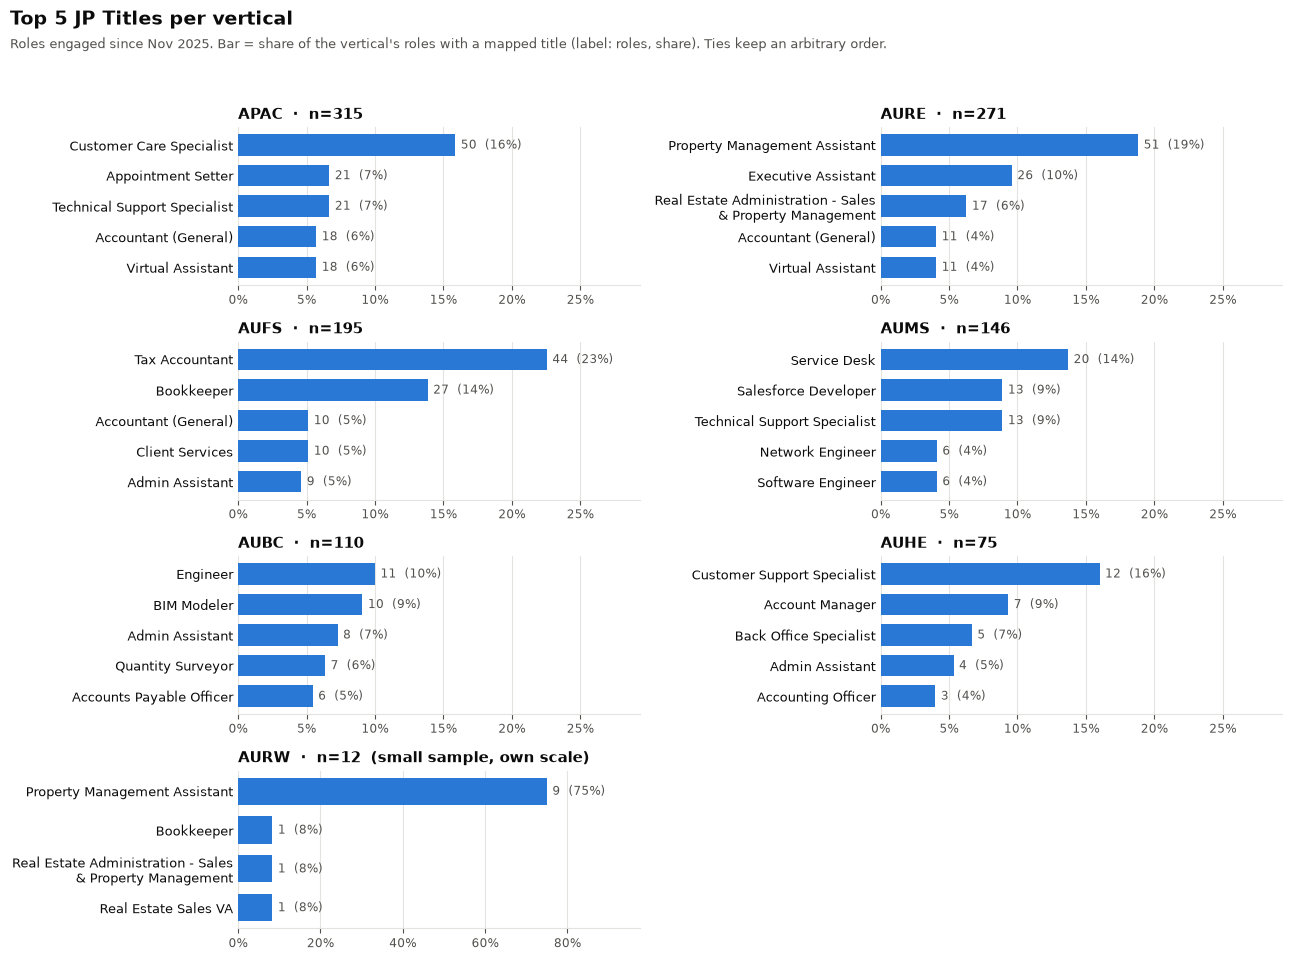

In [26]:
# 4. Top JP Titles per vertical (small multiples; bars = share of that vertical's mapped roles)
import textwrap

MIN_N = 30   # verticals with fewer mapped roles get their own x scale (flagged "small sample")
n_title_by_vertical = roles.dropna(subset=[TITLE_COL])["vertical"].value_counts()
big = top_titles_by_vertical["vertical"].astype(str).map(n_title_by_vertical) >= MIN_N
shared_x_max = top_titles_by_vertical.loc[big, "share"].max() * 1.3

ncols = 2
nrows = -(-len(VERTICAL_ORDER) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 2.4 * nrows))
for ax, v in zip(axes.flat, VERTICAL_ORDER):
    d = top_titles_by_vertical[top_titles_by_vertical["vertical"] == v].iloc[::-1]
    labels = [textwrap.fill(t, 34) for t in d[TITLE_COL].astype(str)]
    bars = ax.barh(labels, d["share"], color=BAR, height=0.7)
    ax.bar_label(bars, labels=[f"{r}  ({s:.0%})" for r, s in zip(d["roles"], d["share"])],
                 padding=4, color=INK_2, fontsize=8.5)
    n = n_title_by_vertical.get(v, 0)
    small = n < MIN_N
    ax.set_title(f"{v}  ·  n={n}" + ("  (small sample, own scale)" if small else ""),
                 fontsize=11, pad=6)
    ax.set_xlim(0, d["share"].max() * 1.3 if small else shared_x_max)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0, labelsize=9)
    ax.tick_params(axis="x", labelsize=8.5)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
for ax in axes.flat[len(VERTICAL_ORDER):]:
    ax.set_visible(False)

fig.suptitle(f"Top {TOP_N_PER_VERTICAL} JP Titles per vertical", x=0.01, y=0.995, ha="left",
             fontsize=14, fontweight="bold")
fig.text(0.01, 0.955, f"Roles {period}. Bar = share of the vertical's roles with a mapped title "
         "(label: roles, share). Ties keep an arbitrary order.", color=INK_2, fontsize=9.5)
plt.tight_layout(rect=(0, 0, 1, 0.945))
plt.show()

### Top JP Title and Category per client

One row per client (shortcode). Share is out of the client's roles with a mapped value.
Ties for top are listed together (" / "), not picked arbitrarily.
Most clients engaged only 1–2 roles, so "top" is only meaningful for the larger ones.

In [27]:
def top_by_group(df, col, group="shortcode"):
    """Most frequent `col` value(s) per `group`, ties joined with ' / '."""
    counts = df.dropna(subset=[col]).groupby([group, col]).size().rename("n").reset_index()
    counts["mapped"] = counts.groupby(group)["n"].transform("sum")
    top = counts[counts["n"] == counts.groupby(group)["n"].transform("max")]
    return (top.sort_values([group, col])
               .groupby(group)
               .agg(top=(col, lambda s: " / ".join(s.astype(str))),
                    roles=("n", "first"),
                    mapped=("mapped", "first"),
                    tied=(col, "size"))
               .assign(share=lambda d: (d["roles"] / d["mapped"]).round(4)))


client_info = (roles.groupby("shortcode")
                    .agg(company_name=("company_name", "first"),
                         vertical=("vertical", "first"),
                         total_roles=("shortcode", "size")))

t = top_by_group(roles, TITLE_COL)
c = top_by_group(roles, CAT_COL)

client_top_roles = (
    client_info
    .join(t[["top", "roles", "share", "tied"]]
          .rename(columns={"top": "top_jp_title", "roles": "top_title_roles",
                           "share": "top_title_share", "tied": "titles_tied"}))
    .join(c[["top", "roles", "share", "tied"]]
          .rename(columns={"top": "top_jp_category", "roles": "top_cat_roles",
                           "share": "top_cat_share", "tied": "categories_tied"}))
    .astype({"top_title_roles": "Int64", "top_cat_roles": "Int64"})   # stay whole numbers when a client has no mapped value
    .sort_values(["total_roles", "company_name"], ascending=[False, True])
)
print(f"{len(client_top_roles)} clients | "
      f"{(client_top_roles['total_roles'] >= 5).sum()} with 5+ roles")

329 clients | 55 with 5+ roles


In [28]:
# Largest 25 clients (change the number, or filter e.g. client_top_roles.query("vertical == 'AUFS'"))
(client_top_roles.head(25)
   .style.format({"top_title_share": "{:.0%}", "top_cat_share": "{:.0%}"}, na_rep="—"))

,company_name,vertical,total_roles,top_jp_title,top_title_roles,top_title_share,titles_tied,top_jp_category,top_cat_roles,top_cat_share,categories_tied
shortcode,,,,,,,,,,,
NEXONAU,Nexon Asia Pacific Pty Ltd,AUMS,69,Service Desk,20,33%,1,BPO Travel/Hospitality,20,32%,1
SQSP,Squarespace Ireland Limited,APAC,65,Customer Care Specialist,48,75%,1,BPO Voice,48,77%,1
FINDEX,Findex (Aust) Pty Ltd,AUFS,50,Client Services,9,19%,1,Accounting,31,65%,1
NEXGEN,Nexgen Investment Group Pty Ltd,APAC,43,Appointment Setter,21,60%,1,BPO Voice,22,63%,1
J4RVIS,J4RVIS PTY LTD,AUMS,27,Salesforce Developer,12,48%,1,IT Software Development,16,64%,1
RSMAU,RSM Australia Pty Ltd,AUFS,27,Tax Accountant,16,62%,1,Accounting,21,81%,1
SWHOTSOL,Switch Hotels Solutions Pty Ltd,APAC,26,Virtual Assistant,16,64%,1,Virtual Assistant,16,64%,1
VISORY,Visory Pty Ltd,AUFS,21,Bookkeeper,18,95%,1,Accounting,19,100%,1
APTOURING,Australian Pacific Touring Pty Ltd,APAC,19,Customer Support Specialist,10,53%,1,Accounting,10,53%,1


## Exports (clipboard)

Run one at a time.

In [29]:
apac_roles_12m_filled.to_clipboard()

In [30]:
apac_roles_12m.to_clipboard()

In [31]:
apac_roles_12m[['JP Title (All)']].drop_duplicates().to_clipboard()